In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter

import seaborn as sns
import tensorflow as tf

#for your homework
np.random.seed(10327798)
tf.random.set_seed(10327798)

In [54]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [55]:
#use the EEG dataset that we used for Lecture 1.
#problems importing from openml
"""
from sklearn.datasets import fetch_openml
eeg = fetch_openml(data_id=1471,as_frame= True)
#synthesize timestamps
increment = 117 / len (eeg[ 'data' ])
index = np.linspace(
start= 0 ,
stop=increment* len (eeg[ 'data' ]),
num= len (eeg[ 'data' ]))
ts_index = pd.to_datetime(index, unit= 's' ,origin = '2022-1-3 15:30:00')  #convert to seconds
"""

"\nfrom sklearn.datasets import fetch_openml\neeg = fetch_openml(data_id=1471,as_frame= True)\n#synthesize timestamps\nincrement = 117 / len (eeg[ 'data' ])\nindex = np.linspace(\nstart= 0 ,\nstop=increment* len (eeg[ 'data' ]),\nnum= len (eeg[ 'data' ]))\nts_index = pd.to_datetime(index, unit= 's' ,origin = '2022-1-3 15:30:00')  #convert to seconds\n"

In [56]:
#can get the arff file from class files or kaggle
from scipy.io import arff
arff = arff.loadarff('/content/drive/MyDrive/Colab Notebooks/EEGEyeState.arff')
eeg = pd.DataFrame(arff[0])
eeg = eeg.iloc[:,0:14]  #ignore the eye state data

In [57]:
# in this case, we use all 14 channels so that this is multivariate timeseries
# the input u(t) is a vector at each point in time <u_1(t), u_2(t), .... u_14(t)>

#synthesize timestamps
increment = 117 / len (eeg)
index = np.linspace(
start= 0 ,
stop=increment* len (eeg),
num= len (eeg))

ts_index = pd.to_datetime(index, unit= 's' ,origin = '2022-1-3 15:30:00')  #convert to seconds

In [58]:
eeg.iloc[:,0:14].shape

(14980, 14)

In [59]:
#make a dataframe out of this. Series usually only have a single value;  we need a dataframe for all 14.
#   remember that dataframes look like spreadsheets.
eeg_df = pd.DataFrame(data=eeg.values, index=ts_index)

In [60]:
# there is an artifact at 1:10, so select a slice of time before
slicing = (eeg_df.index >= '2022-1-3 15:30:08' ) & (eeg_df.index <= '2022-1-3 15:31:10.000000000' )
#the result is still a pandas series, with timestamp, value pairs.

/tmp/ipython-input-267977326.py:4: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  plt.plot(eeg_df.loc[slicing,1:13])   #there are 14 columns total


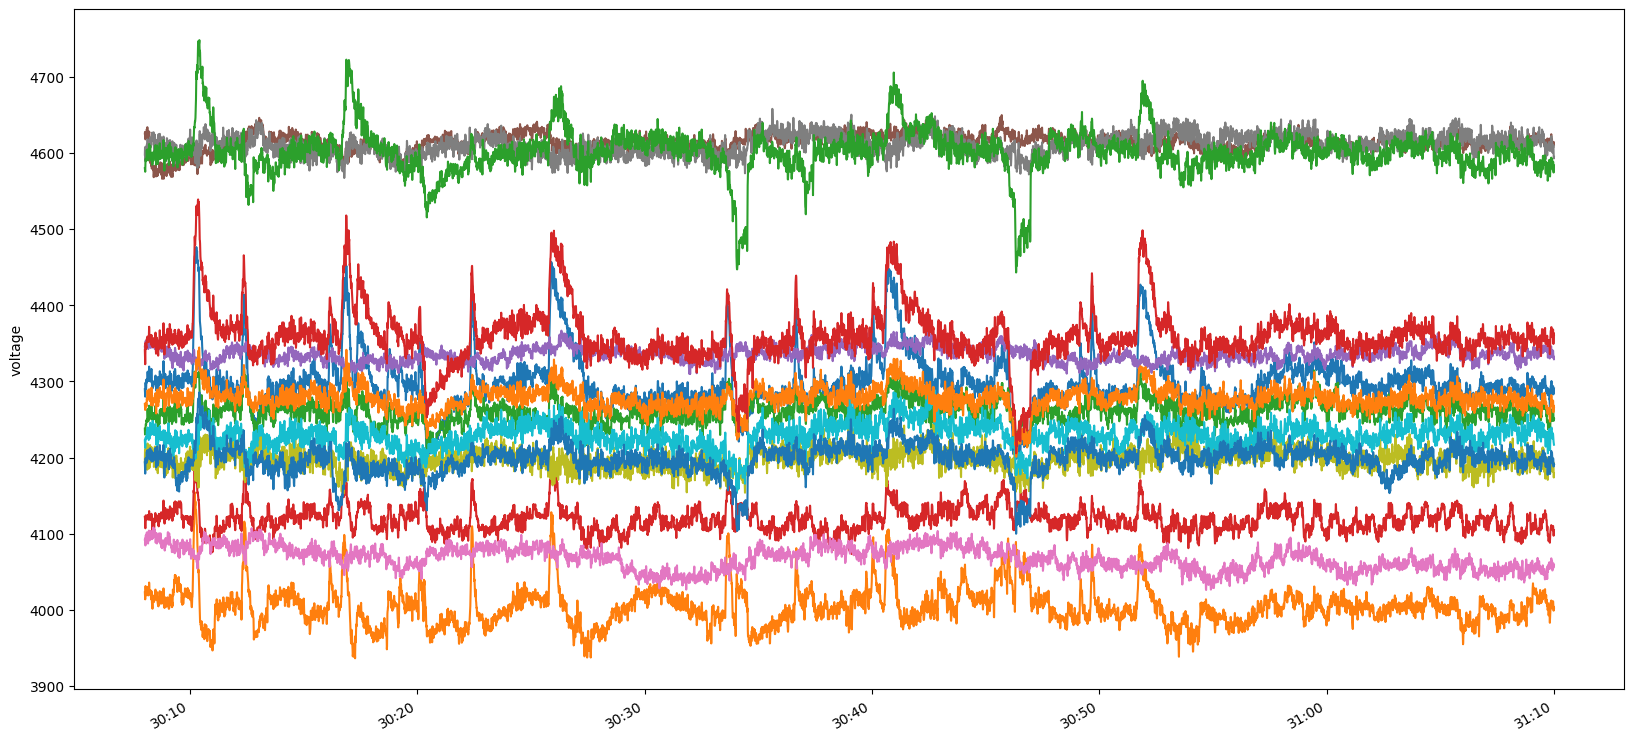

In [61]:
#same time formatter we used before.  look at the raw data
date_formatter = DateFormatter( "%M:%S" )  #just show minutes:seconds
ax = eeg_df.loc[slicing,0].plot(figsize=( 20 , 10 ))  #will use the same axes for all; set dateformatter based on first
plt.plot(eeg_df.loc[slicing,1:13])   #there are 14 columns total
ax.xaxis.set_major_formatter(date_formatter)
plt.ylabel( 'voltage' );



In [62]:
#scale the range.  scale separately for each of the 14 data channels
from sklearn.preprocessing import StandardScaler   #use standard normal (mean 0, std 1) rather than min/max scaler here
scaler = StandardScaler()
scaler.fit(eeg_df[slicing])  #use only the sliced data for the fit
eeg_scaled = scaler.transform(eeg_df[slicing])  #from here on we use only the sliced data
eeg_scaled_df= pd.DataFrame(data=eeg_scaled, index=ts_index[slicing])


In [63]:
#predict 16 lagged time-steps where we have 14 variables (electrodes) at each timestep.
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
predict_length = 16
generator14 = TimeseriesGenerator(eeg_scaled_df.values, eeg_scaled_df.values, length =predict_length , batch_size=16)  #use at least 14 points because 14 dimensions


In [64]:
from tensorflow.python.keras.engine.base_layer_utils import uses_keras_history
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Reshape, Flatten, Input
from tensorflow.keras.layers import MultiHeadAttention, LayerNormalization

In [65]:
n_features = 14  #this is the number of EEG data channels
num_heads = 1    #for multi-head attention.  keep it simple for now.
x = Input((predict_length, n_features))   #predict-length, same as for an RNN
#here is the standard Keras multi-head SDPA layer.  We use the same input for q, k, and v
attention_output = MultiHeadAttention(num_heads=num_heads, key_dim=n_features)(query=x,value=x,key=x)
#normalization.  this layer allows trainable linear scaling z -> az + b
#note the bypass, adding x to the SDPA output
normalized_attention = LayerNormalization()(x + attention_output)
#flatten everything (works ok if there are multiple heads)
y = Flatten()(normalized_attention)
#output will predict the next value
#Note that in many cases, including multi-layered SDPA, the output would be predict_length x n_features
z = Dense(n_features)(y)
model1 = Model(inputs=x, outputs=z, name="model1")
model1.compile(optimizer='adam', loss='mse')
model1.summary()

Model: "model1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 16, 14)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 16, 14)    │        840 │ input_layer_1[0]… │
│ (MultiHeadAttentio… │                   │            │ input_layer_1[0]… │
│                     │                   │            │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 16, 14)    │          0 │ input_layer_1[0]… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 16, 14)    │         28 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 224)       │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 14)        │      3,150 │ flatten_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,018 (15.70 KB)

 Trainable params: 4,018 (15.70 KB)

 Non-trainable params: 0 (0.00 B)

In [66]:
#show all the components of the network, including the SDPA input and output matrix kernels
for i in range(len(model1.weights)):
  print(model1.weights[i].path, model1.weights[i].shape)

multi_head_attention_1/query/kernel (14, 1, 14)
multi_head_attention_1/query/bias (1, 14)
multi_head_attention_1/key/kernel (14, 1, 14)
multi_head_attention_1/key/bias (1, 14)
multi_head_attention_1/value/kernel (14, 1, 14)
multi_head_attention_1/value/bias (1, 14)
multi_head_attention_1/attention_output/kernel (1, 14, 14)
multi_head_attention_1/attention_output/bias (14,)
layer_normalization_1/gamma (14,)
layer_normalization_1/beta (14,)
dense_1/kernel (224, 14)
dense_1/bias (14,)


In [67]:
#training.  Tensorflow is strongly optimized for this
model1.fit(generator14,epochs=5)

Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


496/496 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 1.0891
Epoch 2/5
496/496 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3944
Epoch 3/5
496/496 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3130
Epoch 4/5
496/496 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2740
Epoch 5/5
496/496 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2360


<Axes: >

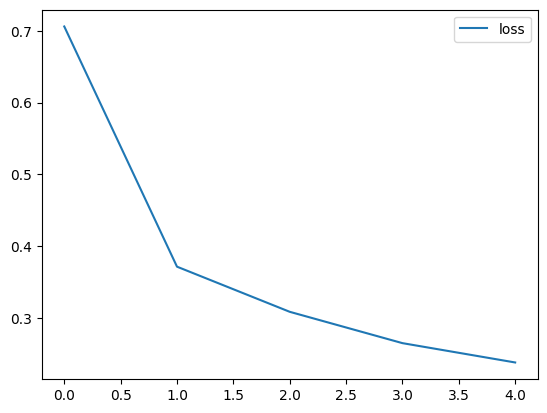

In [68]:
losses = pd.DataFrame(model1.history.history)
losses.plot()

In [69]:
#get the model predictions for all timepoints
predicted_outputs = model1.predict(generator14)  #this is a 14 element vector for each time point
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length
predict_df = pd.DataFrame(data=predicted_outputs, index=eeg_scaled_df.index[predict_length:])  #14 columns plus the timestamp column
orig_df = pd.DataFrame(data=eeg_scaled_df[predict_length:], index=eeg_scaled_df.index[predict_length:len(eeg_scaled_df)])


496/496 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


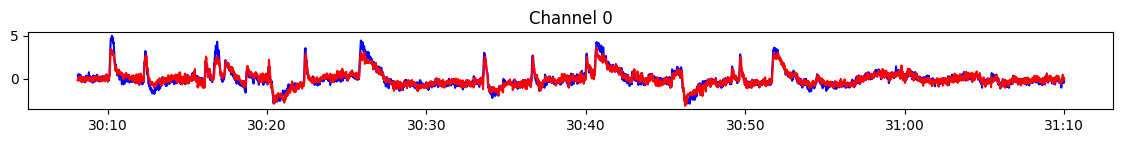

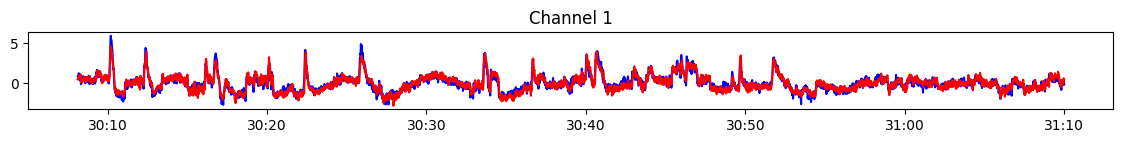

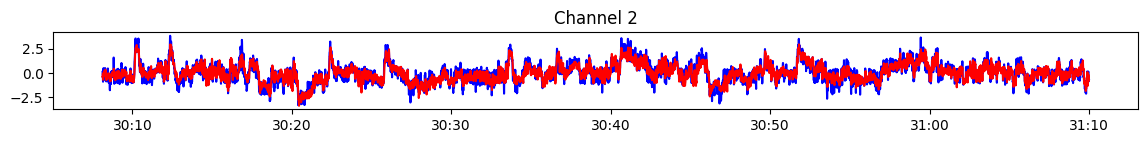

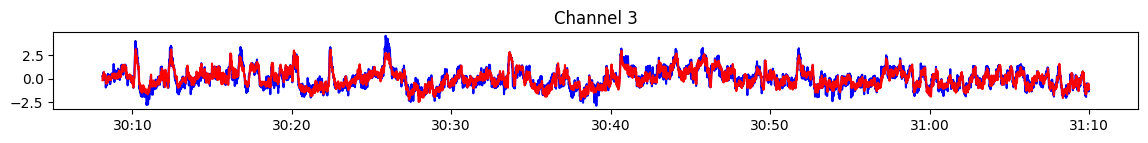

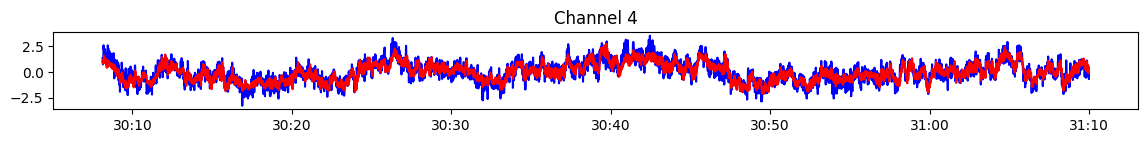

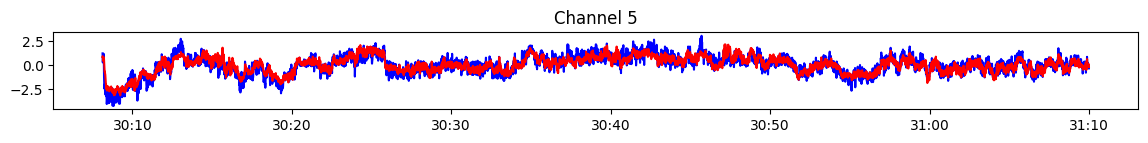

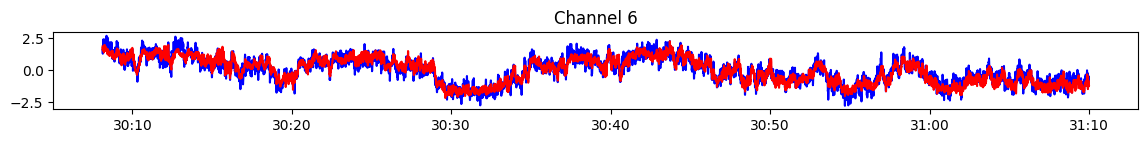

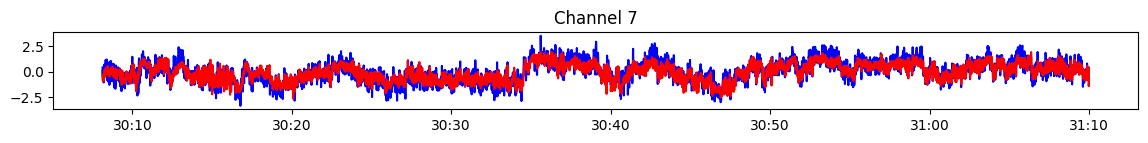

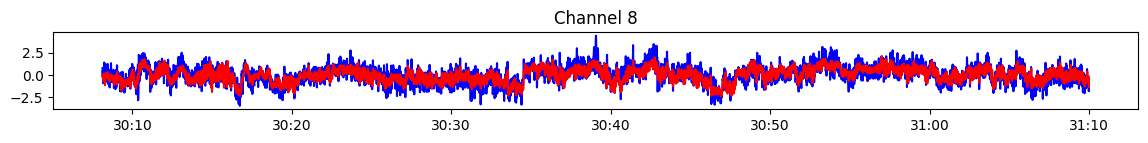

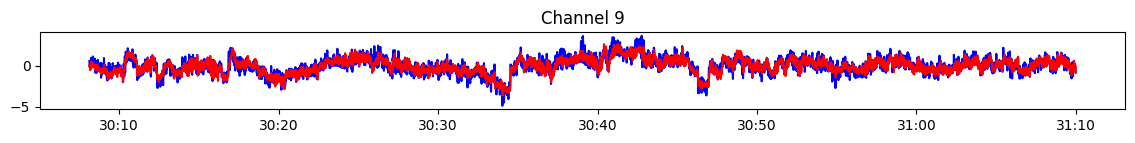

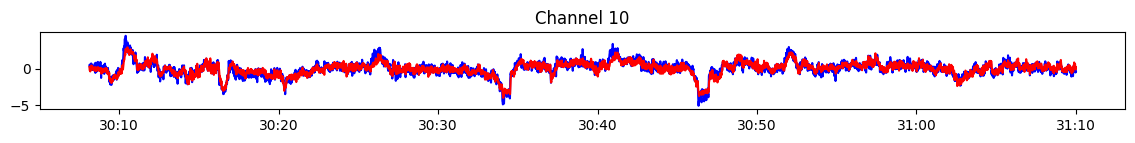

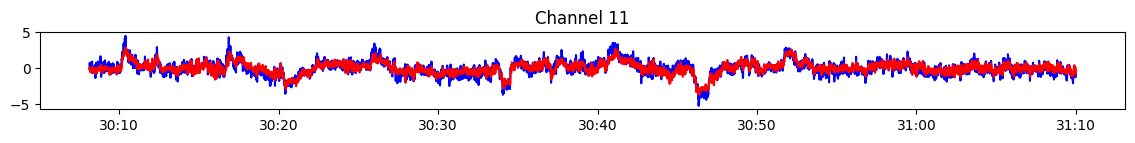

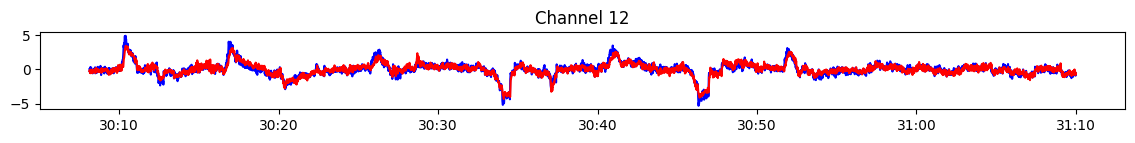

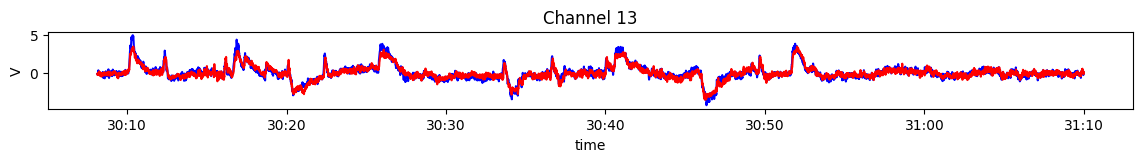

In [70]:
#show the model predictions.  each output prediction is formed using the previous 14 input datapoints
for n in range(n_features):
  plt.figure(figsize=(14,1),linewidth=.1)
  ax = plt.gca()
  ax.xaxis_date()
  ax.xaxis.set_major_formatter(date_formatter)
  plt.plot(orig_df[n],'b')  #compare one column at a time
  plt.plot(predict_df[n],'r')
  plt.title('Channel {}'.format(n))
plt.ylabel('V')
plt.xlabel('time');


In [71]:
from tensorflow.python.keras.engine.base_layer_utils import uses_keras_history
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Reshape, Flatten, Input
from tensorflow.keras.layers import MultiHeadAttention, LayerNormalization
n_features = 14
n_hidden = 4
num_heads = 1
x = Input((predict_length, n_features))
h = Dense(n_hidden)(x)  #reduces to n_hidden instead of n_features
attention_output = MultiHeadAttention(num_heads=num_heads, key_dim=n_hidden)(query=h,value=h,key=h)
normalized_attention = LayerNormalization()(h + attention_output)
y = Flatten()(normalized_attention)
z = Dense(n_features)(y)
model2 = Model(inputs=x, outputs=z, name="model2")
model2.compile(optimizer='adam', loss='mse')
model2.summary()

Model: "model2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 16, 14)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 16, 4)     │         60 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 16, 4)     │         80 │ dense_2[0][0],    │
│ (MultiHeadAttentio… │                   │            │ dense_2[0][0],    │
│                     │                   │            │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 16, 4)     │          0 │ dense_2[0][0],    │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 16, 4)     │          8 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 64)        │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 14)        │        910 │ flatten_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,058 (4.13 KB)

 Trainable params: 1,058 (4.13 KB)

 Non-trainable params: 0 (0.00 B)

In [72]:
for i in range(len(model2.weights)):
  print(model2.weights[i].path, model2.weights[i].shape)

dense_2/kernel (14, 4)
dense_2/bias (4,)
multi_head_attention_2/query/kernel (4, 1, 4)
multi_head_attention_2/query/bias (1, 4)
multi_head_attention_2/key/kernel (4, 1, 4)
multi_head_attention_2/key/bias (1, 4)
multi_head_attention_2/value/kernel (4, 1, 4)
multi_head_attention_2/value/bias (1, 4)
multi_head_attention_2/attention_output/kernel (1, 4, 4)
multi_head_attention_2/attention_output/bias (4,)
layer_normalization_2/gamma (4,)
layer_normalization_2/beta (4,)
dense_3/kernel (64, 14)
dense_3/bias (14,)


In [73]:
#Note that this is not much faster than model1; GPUs do most of the work in parallel so smaller vectors are not necessarily faster
model2.fit(generator14,epochs=5)

Epoch 1/5
496/496 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 1.3520
Epoch 2/5
496/496 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.7956
Epoch 3/5
496/496 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.7368
Epoch 4/5
496/496 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6210
Epoch 5/5
496/496 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.5823


<Axes: >

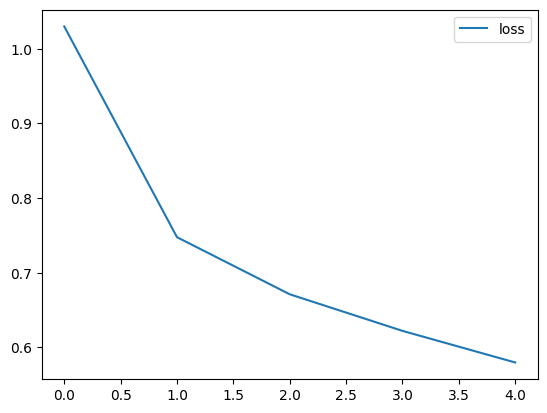

In [74]:
losses = pd.DataFrame(model2.history.history)
losses.plot()

In [75]:
#get the model predictions for all timepoints
predicted_outputs = model2.predict(generator14)  #this is a 14 element vector for each time point
#convert to dataframes with the correct timestamps.  outputs start at t=predict_length
predict_df = pd.DataFrame(data=predicted_outputs, index=eeg_scaled_df.index[predict_length:])  #14 columns plus the timestamp column
orig_df = pd.DataFrame(data=eeg_scaled_df[predict_length:], index=eeg_scaled_df.index[predict_length:len(eeg_scaled_df)])

496/496 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


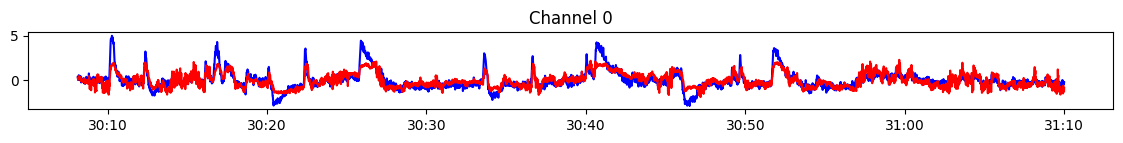

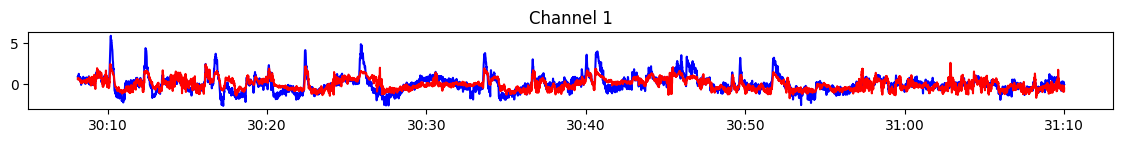

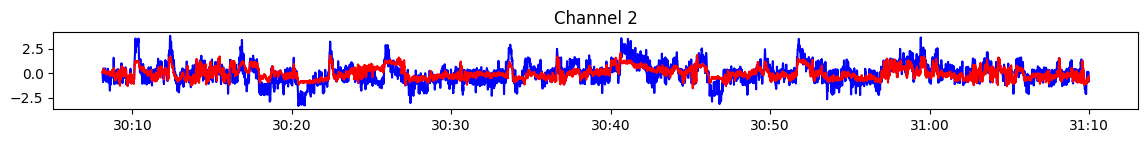

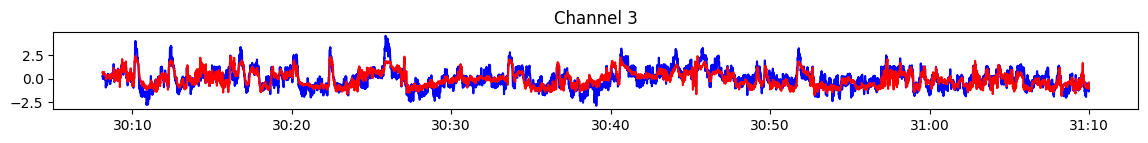

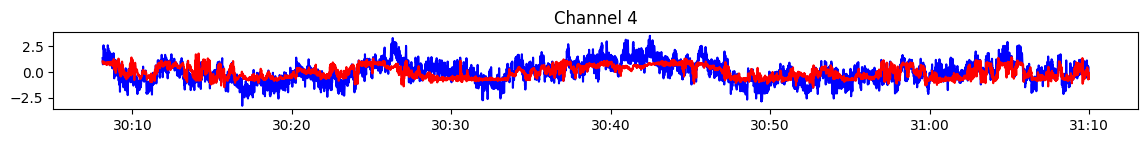

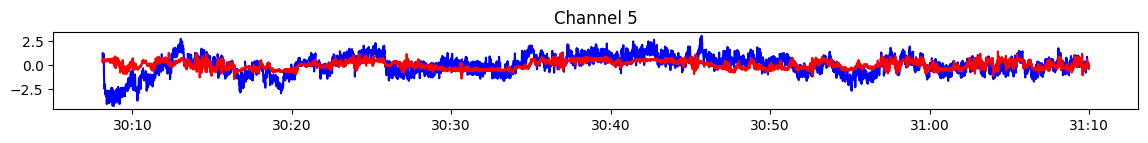

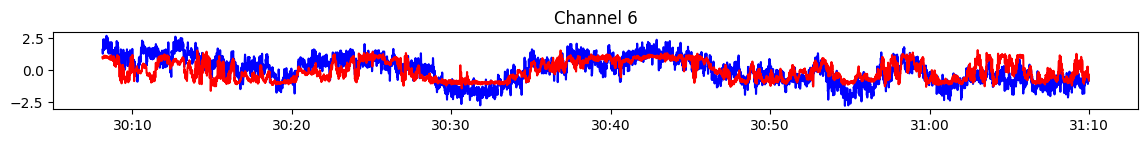

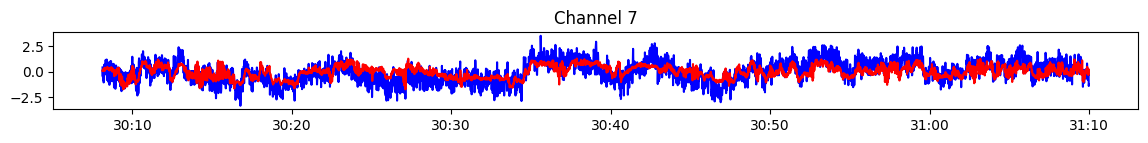

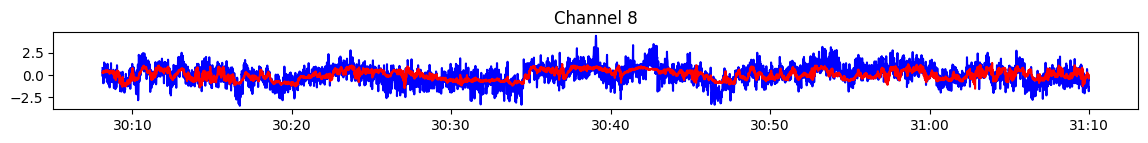

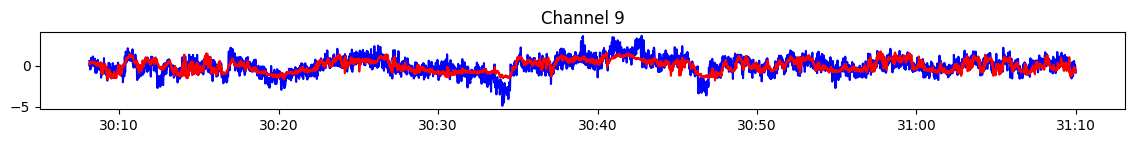

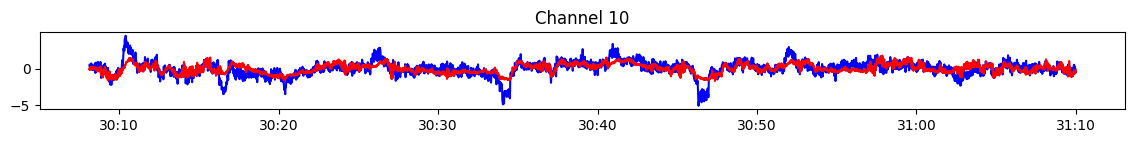

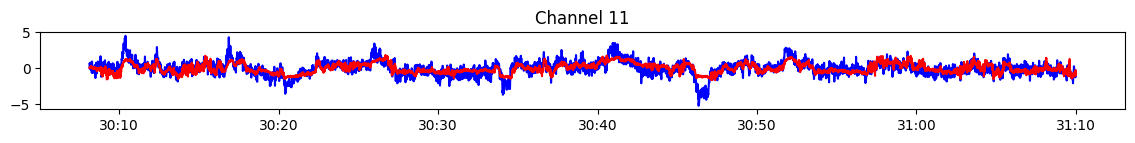

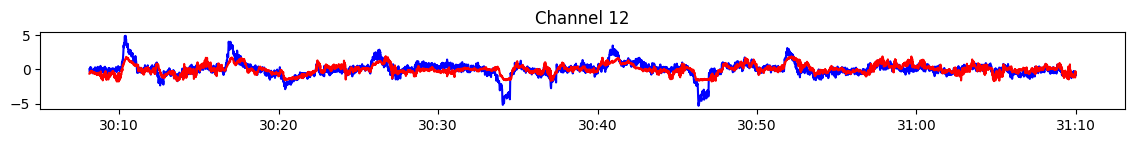

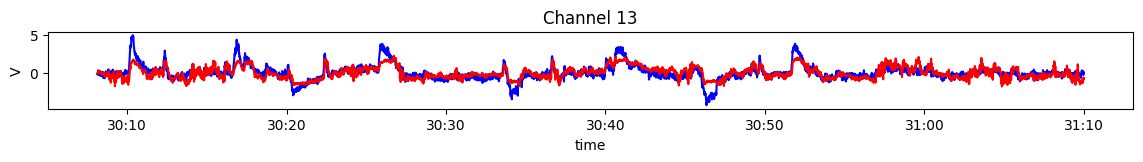

In [76]:
#show the model predictions.  each output prediction is formed using the previous 14 input datapoints
for n in range(n_features):
  plt.figure(figsize=(14,1),linewidth=.1)
  ax = plt.gca()
  ax.xaxis_date()
  ax.xaxis.set_major_formatter(date_formatter)
  plt.plot(orig_df[n],'b')  #compare one column at a time
  plt.plot(predict_df[n],'r')
  plt.title('Channel {}'.format(n))
plt.ylabel('V')
plt.xlabel('time');


In [77]:
#calculate the values of the hidden states h that were learned
#  in other words: what was the useful information sent to the inputs of the SDPA layer?
hidden_states = np.dot(eeg_scaled_df.values,model2.weights[0])
nTimes,nStates = np.shape(hidden_states)

/tmp/ipython-input-930815273.py:3: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  hidden_states = np.dot(eeg_scaled_df.values,model2.weights[0])


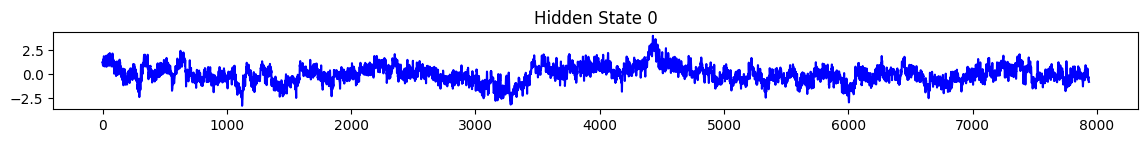

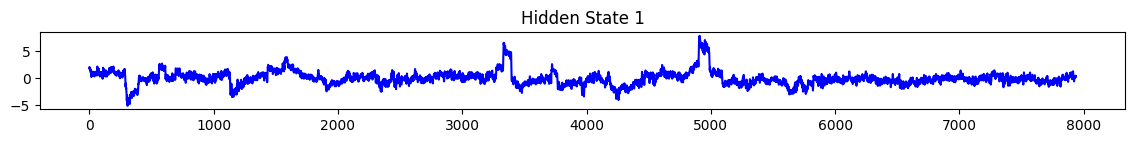

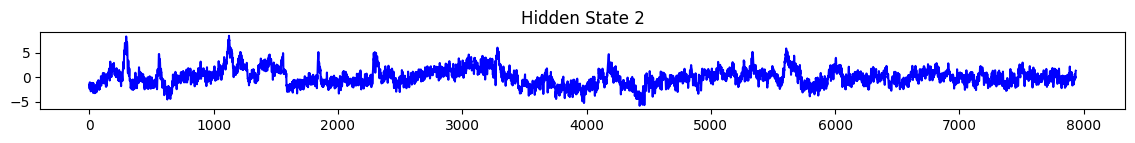

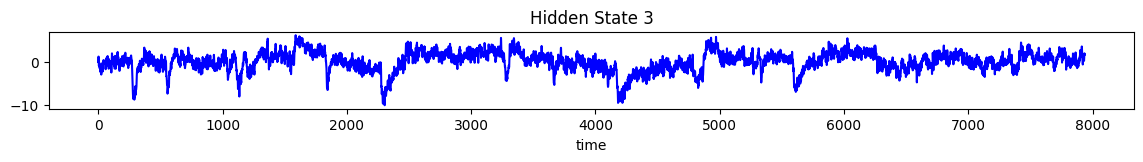

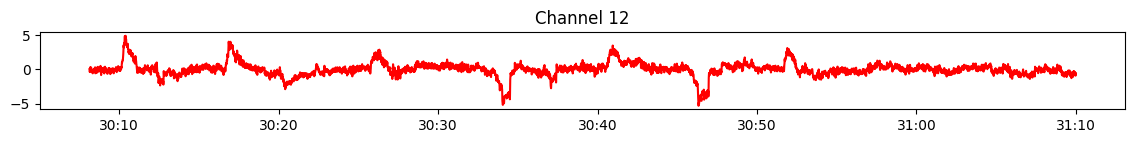

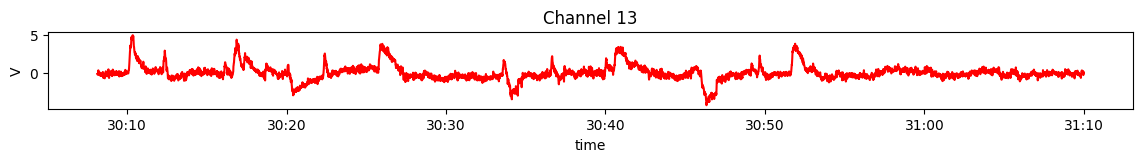

In [78]:
#plot the time values of the hidden states
for n in range(0,nStates):
  plt.figure(figsize=(14,1),linewidth=.1)
  ax = plt.gca()
  plt.plot(hidden_states[:,n],'b')  #compare one column at a time
  plt.title('Hidden State {}'.format(n))
plt.xlabel('time');
#show some of the original data for comparison
for n in range(12,n_features):
  plt.figure(figsize=(14,1),linewidth=.1)
  ax = plt.gca()
  ax.xaxis_date()
  ax.xaxis.set_major_formatter(date_formatter)
  plt.plot(orig_df[n],'r')  #compare one column at a time
  plt.title('Channel {}'.format(n))
plt.ylabel('V')
plt.xlabel('time');


Text(0.5, 1.0, 'rectified EMG and Torque')

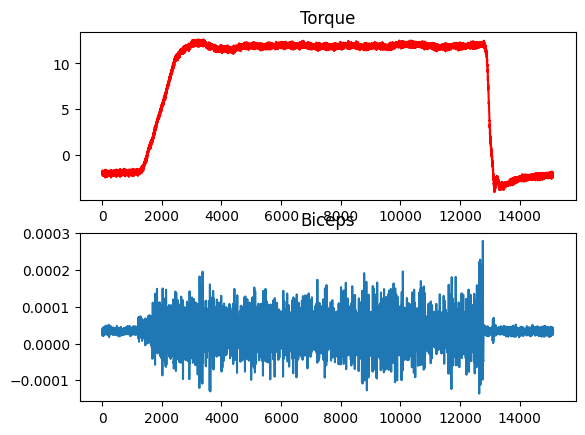

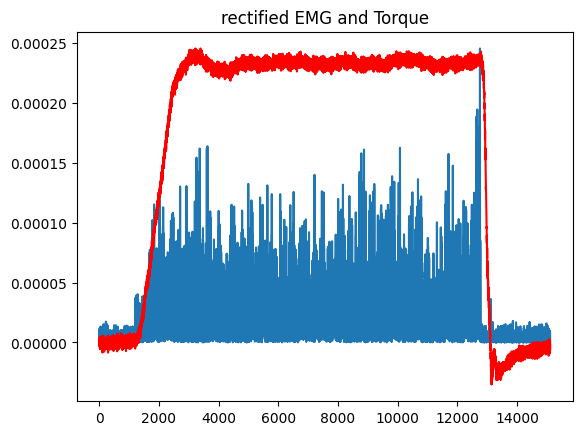

In [79]:
#load the sample EMG data
arEMG = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/EMGdata.csv')
dfEMG = pd.DataFrame(arEMG)
plt.figure()
plt.subplot(211)
plt.plot(dfEMG['Torque'],'r')
plt.title('Torque')
plt.subplot(212)
plt.plot(dfEMG['Biceps'])
plt.title('Biceps')
wave_signal = dfEMG['Torque'].to_numpy()
wave_signal = wave_signal - wave_signal[0:200].mean()  #make start at zero
modulated_signal = dfEMG['Biceps'].to_numpy()
modulated_signal = modulated_signal - modulated_signal[0:200].mean()  #use the first few points to find the zero
modulated_signal = np.absolute(modulated_signal)  #rectify the EMG
time_points = len(wave_signal)
plt.figure()
plt.plot(modulated_signal)
plt.plot(wave_signal * modulated_signal.max()/wave_signal.max(),'r')
plt.title('rectified EMG and Torque')

In [80]:
def to_distributed(data, nstates=128, timepoints=1000):
  d = data - min(data)
  dscale = ((nstates-1)*d/np.max(d))
  vec = np.zeros((timepoints, nstates), dtype = int)
  vec[np.arange(timepoints),dscale.astype(int)] = 1
  return vec

<Figure size 1400x100 with 0 Axes>

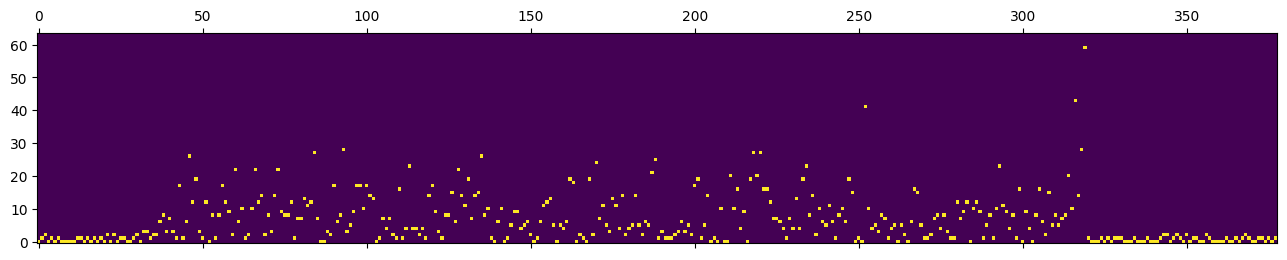

<Figure size 1400x100 with 0 Axes>

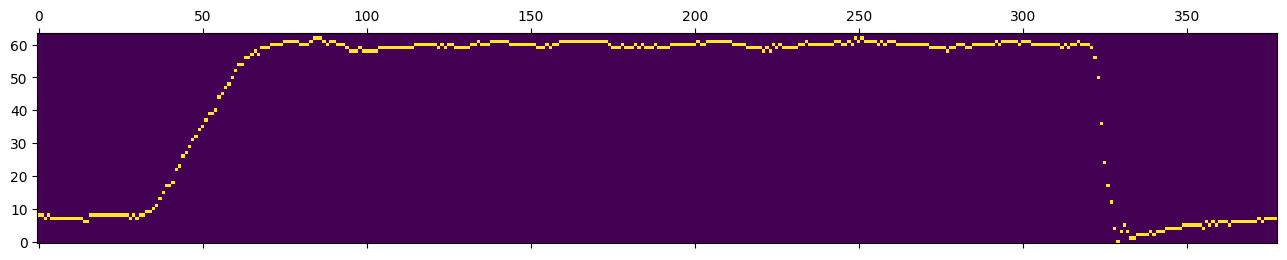

In [81]:
#turn into probability vectors
n_states = 64   #this is arbitrary. sets the precision
vModulated = to_distributed(modulated_signal, n_states, time_points)
dfModulated = pd.DataFrame(data=vModulated, index=np.arange(time_points))
plt.figure(figsize=(14,1))
plt.matshow(vModulated[np.arange(0,time_points,40)].transpose(), origin = 'lower')
vWave = to_distributed(wave_signal, n_states, time_points)
dfWave = pd.DataFrame(data=vWave, index=np.arange(time_points))
plt.figure(figsize=(14,1))
plt.matshow(vWave[np.arange(0,time_points,40)].transpose(), origin = 'lower');

In [82]:
#build the SDPA/Transformer model
#higher predict_length allows the output to be smoother
predict_length = 200
generator15 = TimeseriesGenerator(dfModulated.values, wave_signal, length =predict_length , batch_size=16)

n_features = n_states
n_outputs = 1  #just predicting the torque directly.  alternative is to predict a one-hot coding of torque
num_heads = 1
x = Input((predict_length, n_features))
h = x  #not using dimensionality reduction here
attention_output = MultiHeadAttention(num_heads=num_heads, key_dim=n_features)(query=h,value=h,key=h)
normalized_attention = LayerNormalization()(h + attention_output)
y = Flatten()(normalized_attention)
z = Dense(n_outputs, activation='linear')(y)
model3 = Model(inputs=x, outputs=z, name="model3")
model3.compile(optimizer='adam', loss='mse')
model3.summary()

Model: "model3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 200, 64)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 200, 64)   │     16,640 │ input_layer_3[0]… │
│ (MultiHeadAttentio… │                   │            │ input_layer_3[0]… │
│                     │                   │            │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 200, 64)   │          0 │ input_layer_3[0]… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 200, 64)   │        128 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 12800)     │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 1)         │     12,801 │ flatten_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 29,569 (115.50 KB)

 Trainable params: 29,569 (115.50 KB)

 Non-trainable params: 0 (0.00 B)

In [83]:
model3.fit(generator15, epochs=5)

Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


933/933 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 13.7146
Epoch 2/5
933/933 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 5.5335
Epoch 3/5
933/933 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 4.6482
Epoch 4/5
933/933 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 4.1827
Epoch 5/5
933/933 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 3.3916


<Axes: >

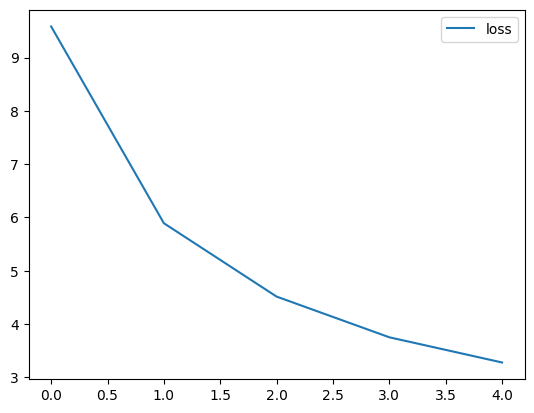

In [84]:
losses = pd.DataFrame(model3.history.history)
losses.plot()

In [85]:
predicted_outputs = model3.predict(generator15)  #this is a 14 element vector for each time point

933/933 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


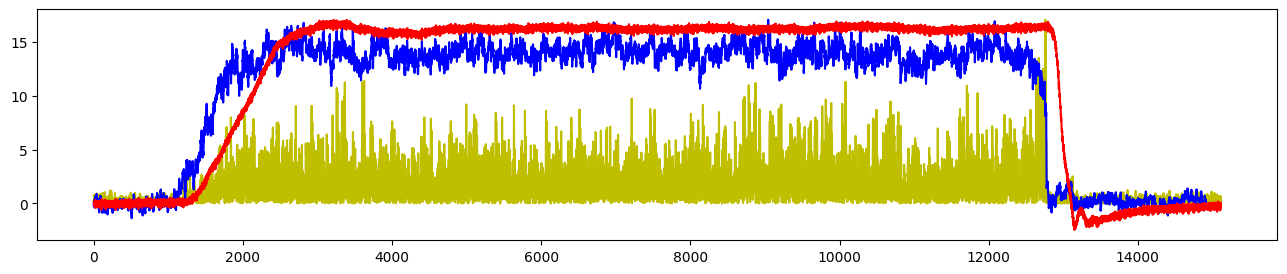

In [86]:
#compare predicted (blue) to true (red) torque
predicted_x = predicted_outputs
plt.figure(figsize=(16,3))
plt.plot(modulated_signal*predicted_x.max()/modulated_signal.max(),'y');
plt.plot(predicted_x,'b');
plt.plot(wave_signal*predicted_x.max()/wave_signal.max(),'r');